# 확률·표본추출 종합 검토

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 결과의 의미 구분

빨간 공 비율 0.1인 상자에서 10회 복원추출하여 빨간 공 4개가 나왔다. 빨간 공이 4개 이상 나올 확률을 계산하시오. 이 확률이 곧 상자 A의 사후확률인지 설명하시오.

In [2]:
from scipy.stats import binom
print('P(R >= 4 | A):', binom.sf(3,10,.1))
L = binom.pmf(4,10,[.1,.8])
print('동일 사전확률일 때 P(A | R=4):', L[0]/L.sum())

P(R >= 4 | A): 0.0127951984
동일 사전확률일 때 P(A | R=4): 0.6696711757404694


## 표본 검토

독립 표본과 자기상관이 있는 열이 같은 주변분포를 가질 수 있다. 아래 두 열의 평균·지연 1 상관계수를 비교하시오. 표본 개수만 같으면 정보량도 같다고 할 수 있는지 설명하시오.

independent mean: -0.025522900314345245 lag1: 0.03486021696126993
correlated mean: 0.06687459874560346 lag1: 0.9558255595197022


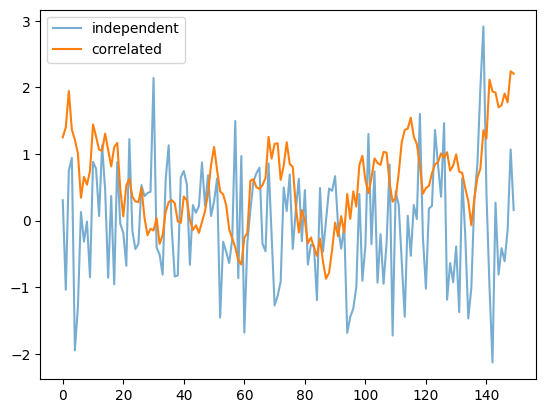

In [3]:
rng = np.random.default_rng(42)
a = rng.normal(size=3000)
b = np.empty(3000); b[0] = rng.normal()
for i in range(1,len(b)): b[i] = .95*b[i-1] + np.sqrt(1-.95**2)*rng.normal()
for name,v in [('independent',a),('correlated',b)]:
    print(name, 'mean:', v.mean(), 'lag1:', np.corrcoef(v[:-1],v[1:])[0,1])
plt.plot(a[:150],alpha=.6,label='independent');plt.plot(b[:150],label='correlated')
plt.legend();plt.show()

## 설명하기

결측·사전확률·조건부독립·수락률·자기상관 중 두 개를 골라, 분석 결과를 잘못 해석할 수 있는 사례를 각각 만드시오. 작은 수치 예로 확인하시오.